# Yield curve analysis

## Importing dependencies

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fixed_income.nss_curve import (
    fit_ns,
    fit_nss,
    nelson_siegel,
    nelson_siegel_svensson,
)
from fixed_income.grid_search import ns_linesearch, nss_gridsearch

## Importing the dataframe

The csv file contains treasury par yields. 
Source of the date is a CSV file that is available on treasury.gov.

In [83]:
yield_df = pd.read_csv("/workspaces/fixed-income/data/raw/treasury_yields_2026.csv")

yield_df = yield_df.rename(columns={"Date": "date"})
yield_df["date"] = pd.to_datetime(yield_df["date"])
yield_df.head()

,date,1 Mo,1.5 Month,2 Mo,3 Mo,4 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
0,2026-11-12,4.12,4.18,4.26,4.32,4.35,4.42,4.65,4.86,4.90,4.95,5.02,5.10,5.48,5.43
1,2026-11-10,4.05,4.16,4.21,4.30,4.28,4.38,4.56,4.73,4.74,4.81,4.89,4.98,5.39,5.35
2,2026-11-09,4.04,4.13,4.19,4.24,4.20,4.26,4.38,4.56,4.58,4.67,4.76,4.88,5.29,5.26
3,2026-11-06,4.02,4.07,4.15,4.19,4.19,4.23,4.33,4.51,4.59,4.64,4.74,4.86,5.29,5.26
4,2026-11-05,4.03,4.07,4.15,4.17,4.16,4.19,4.28,4.46,4.53,4.59,4.70,4.84,5.27,5.25


## Fitting Nelson-Siegel (NS) and Nelson-Siegel-Svensson (NSS) curves
US treasury par yields are not market instruments rates; they are rates that are derived by fitting a curve to bid-side market price quotations. Therefore, fitting NS and NSS curves does not independently reconstruct a yield curve but they can provide estimates for missing maturities.


In [84]:
# Extract the dataframe row for a specific date and prepare it for fitting NS and NSS curves

DATE = "2026-11-12"
rates = (
    yield_df.loc[yield_df["date"] == DATE]
    .drop(columns="date")
    .to_numpy(dtype=float)
    .flatten()
)
rates = rates / 100


# Create an array of maturities in years

maturities = np.array(
    [
        0.0833,
        0.125,
        0.1666,
        0.25,
        0.3333,
        0.5,
        1,
        2,
        3,
        5,
        7,
        10,
        20,
        30,
    ]
)

First we fit NS and NSS curves with default lambda value of 0.2 (for NS) and default lambda and mu values of 0.2 and 0.1 (for NSS) which are specified in fit_ns() and fit_nss() respectively.

In [85]:
ns_params = fit_ns(maturities, rates).x

# Add the default value of lambda, as set in fit_ns,
# to array of betas:
LMBDA = 0.2

ns_params = np.append(ns_params, LMBDA)
print(ns_params)

[ 0.05416959 -0.01148075  0.01143224  0.2       ]


In [86]:
nss_params = fit_nss(maturities, rates).x

# Add the default value of lambda and mu, as set in fit_nss,
# to array of betas:
LMBDA = 0.2
MU = 0.1

nss_params = np.append(nss_params, [LMBDA, MU])
print(nss_params)

[ 0.07117749 -0.02879137  0.03224876 -0.06213111  0.2         0.1       ]


After obtaining the parameters of each curve, we calculate the rate for each maturity and plot them against the actual part yield curve.

In [87]:
fitted_ns = nelson_siegel(maturities, *ns_params)
fitted_nss = nelson_siegel_svensson(maturities, *nss_params)

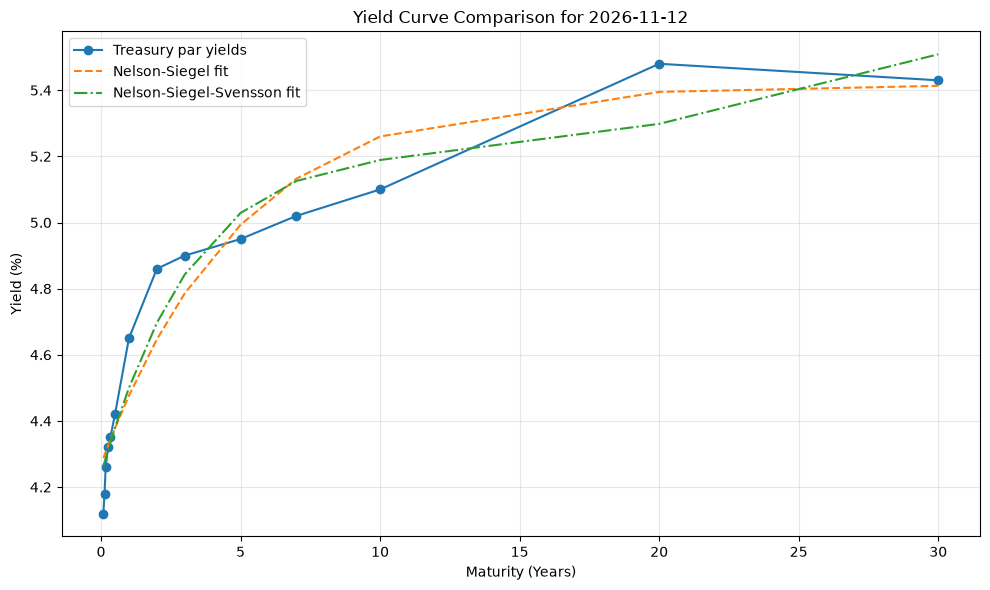

In [88]:
plt.figure(figsize=(10, 6))

plt.plot(maturities, rates * 100, marker="o", label="Treasury par yields")
plt.plot(maturities, fitted_ns * 100, linestyle="--", label="Nelson-Siegel fit")
plt.plot(
    maturities, fitted_nss * 100, linestyle="-.", label="Nelson-Siegel-Svensson fit"
)

plt.xlabel("Maturity (Years)")
plt.ylabel("Yield (%)")
plt.title(f"Yield Curve Comparison for {DATE}")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Calibrating Nelson-Siegel (NS) and Nelson-Siegel-Svensson (NSS) curves
We perform a line search for the NS model and grid search for NSS model and find the optimized lambda and lambda, mu for them respectivly.
Three minimization criteria are provided:
1. RSME (Root Mean Squared Error): minimizes overall good fit 
2. MAE (Mean Absolute Error): less sesitivity to outliers than RSME
3. Max error: minimizes smallest largest absolute error

In [89]:
linesearch_result = ns_linesearch(maturities, rates, lambda_values=None)
print(linesearch_result)

           Lambda  Mu  Criterion Value   Beta0   Beta1   Beta2
Criterion                                                     
RMSE          0.7 NaN           0.0010  0.0540 -0.0122  0.0002
MAE           0.7 NaN           0.0008  0.0540 -0.0122  0.0002
Max error     0.5 NaN           0.0014  0.0544 -0.0123  0.0022


In [90]:
gridsearch_result = nss_gridsearch(
    maturities, rates, lambda_values=None, mu_values=None
)
print(gridsearch_result)

           Lambda   Mu  Criterion Value   Beta0   Beta1   Beta2   Beta3
Criterion                                                              
RMSE         0.05  1.0           0.0003  0.0295  0.0111  0.0633  0.0178
MAE          0.05  1.0           0.0002  0.0295  0.0111  0.0633  0.0178
Max error    0.05  1.0           0.0006  0.0295  0.0111  0.0633  0.0178


In [91]:
ns_params_opt = fit_ns(maturities, rates, lmbda=0.7).x

# Addind lambda to array of betas:
LMBDA = linesearch_result.iloc[0, 0]  # Best lambda based on RMSE

ns_params_opt = np.append(ns_params_opt, LMBDA)
print(ns_params_opt)

[ 5.40416071e-02 -1.21528464e-02  1.74581408e-04  7.00000000e-01]


In [92]:
nss_params_opt = fit_nss(maturities, rates, lmbda=0.05, mu=1).x

# Addind lambda and mu to array of betas:
LMBDA = gridsearch_result.iloc[0, 0]  # Best lambda based on RMSE
MU = gridsearch_result.iloc[0, 1]  # Best mu based on RMSE

nss_params_opt = np.append(nss_params_opt, [LMBDA, MU])
print(nss_params_opt)

[0.02952946 0.01114067 0.06328899 0.01782043 0.05       1.        ]


In [93]:
fitted_ns_opt = nelson_siegel(maturities, *ns_params_opt)
fitted_nss_opt = nelson_siegel_svensson(maturities, *nss_params_opt)

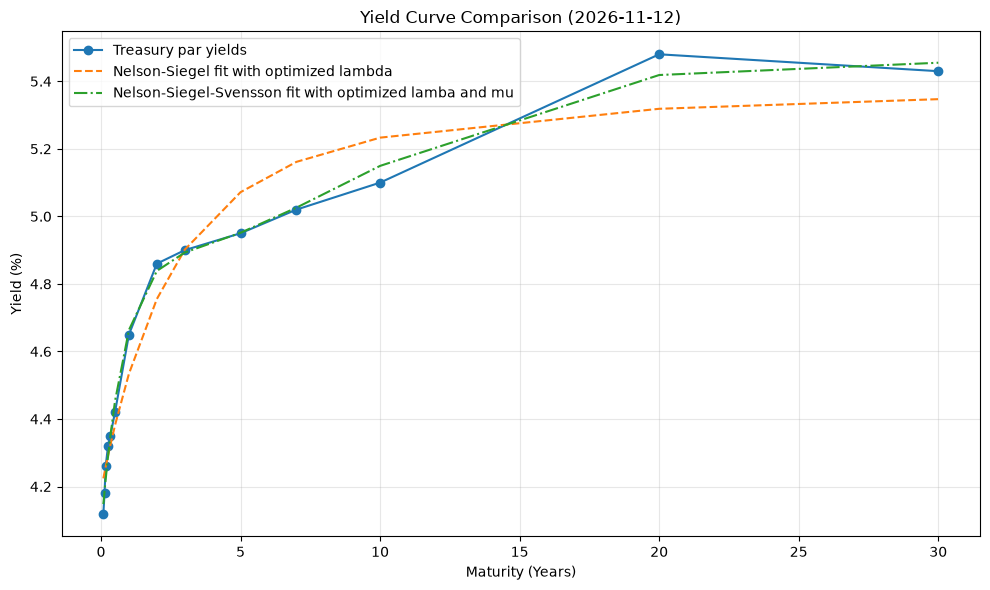

In [94]:
plt.figure(figsize=(10, 6))

plt.plot(maturities, rates * 100, marker="o", label="Treasury par yields")
plt.plot(
    maturities,
    fitted_ns_opt * 100,
    linestyle="--",
    label="Nelson-Siegel fit with optimized lambda",
)
plt.plot(
    maturities,
    fitted_nss_opt * 100,
    linestyle="-.",
    label="Nelson-Siegel-Svensson fit with optimized lamba and mu",
)

plt.xlabel("Maturity (Years)")
plt.ylabel("Yield (%)")
plt.title(f"Yield Curve Comparison ({DATE})")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Comparing curves with default parameters to curves with optimized parameters

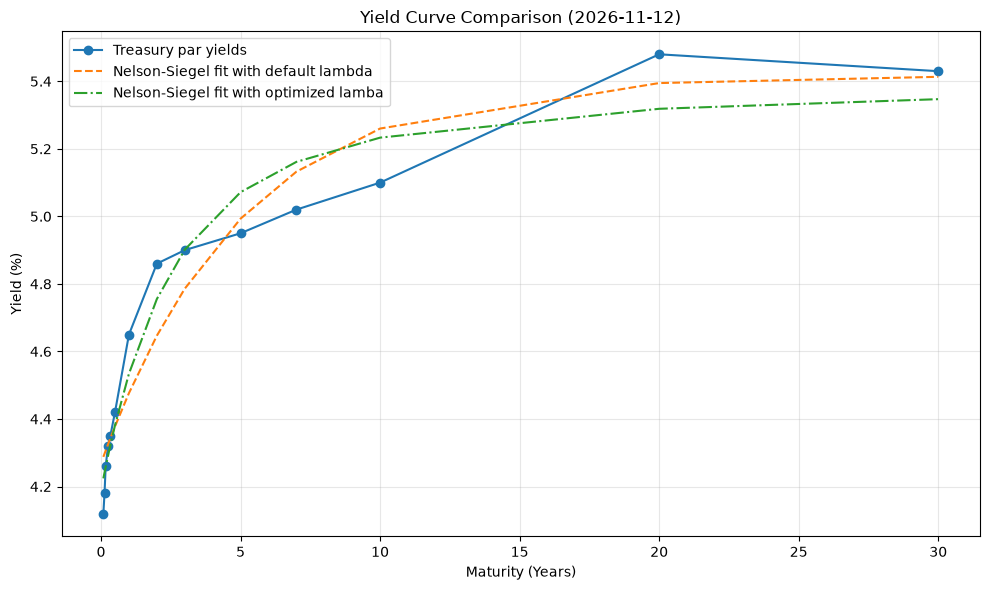

In [95]:
plt.figure(figsize=(10, 6))

plt.plot(maturities, rates * 100, marker="o", label="Treasury par yields")
plt.plot(
    maturities,
    fitted_ns * 100,
    linestyle="--",
    label="Nelson-Siegel fit with default lambda",
)
plt.plot(
    maturities,
    fitted_ns_opt * 100,
    linestyle="-.",
    label="Nelson-Siegel fit with optimized lamba",
)

plt.xlabel("Maturity (Years)")
plt.ylabel("Yield (%)")
plt.title(f"Yield Curve Comparison ({DATE})")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

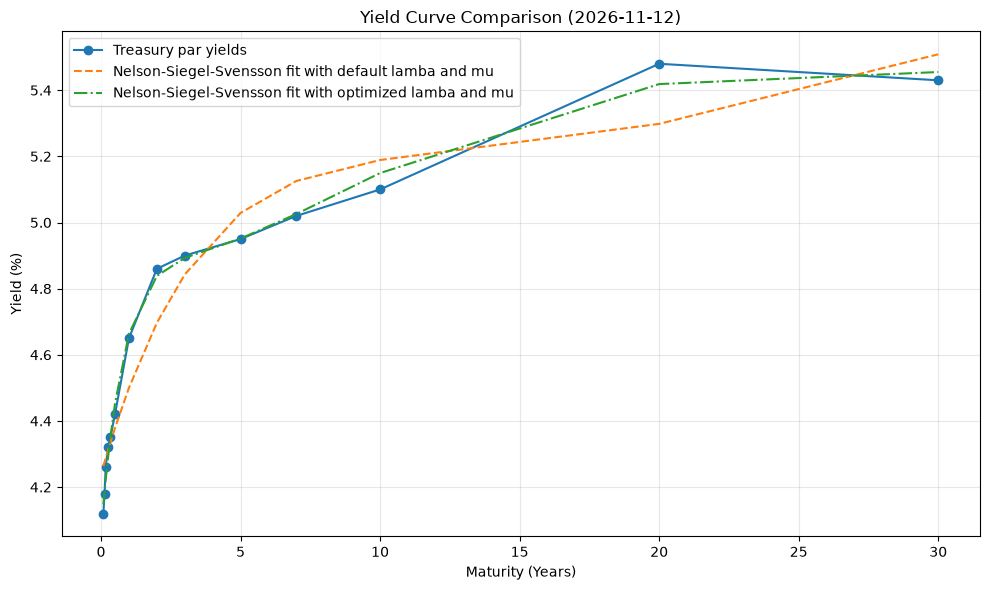

In [96]:
plt.figure(figsize=(10, 6))

plt.plot(maturities, rates * 100, marker="o", label="Treasury par yields")
plt.plot(
    maturities,
    fitted_nss * 100,
    linestyle="--",
    label="Nelson-Siegel-Svensson fit with default lamba and mu",
)
plt.plot(
    maturities,
    fitted_nss_opt * 100,
    linestyle="-.",
    label="Nelson-Siegel-Svensson fit with optimized lamba and mu",
)

plt.xlabel("Maturity (Years)")
plt.ylabel("Yield (%)")
plt.title(f"Yield Curve Comparison ({DATE})")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()